**Estado: Cerrado exploratorio; resultado negativo del protocolo.** Cierre: 2026-10-26. Conclusiones y límites al final del notebook. [Tabla global de benchmarks](../../BENCHMARKS.md).


# Diagnóstico de la onda: representación, interpolación y escala de coeficientes

Se conserva el piloto original y se estudian dos preguntas: ¿la base PCA con coeficientes conocidos puede satisfacer aproximadamente la física?, ¿estandarizar sus coeficientes mejora el entrenamiento sin cambiar datos, k, arquitectura, pérdida ni pasos? Los outputs provienen de artefactos guardados.

## Control oráculo previo

Se proyecta la solución analítica sobre los modos PCA ajustados con entrenamiento. Sus coeficientes son funciones analíticas del tiempo, por lo que JAX calcula u_tt y u_xx sin diferencias finitas. Este control no se entrena ni se usa como competidor. Se evalúan la referencia directa, la misma base PCA expresada en senos conocidos y su interpolación spline C2 usada por la red. Así se distingue compresión espacial de error de interpolación.

El residuo normalizado es RMS(u_tt − 4u_xx) / [RMS(u_tt) + RMS(4u_xx)]. Se muestran también los valores absolutos: normalizar el diagnóstico no cambia la pérdida de entrenamiento. La pérdida oráculo suma los mismos cinco términos con peso uno; la solución nula falla en datos y desplazamiento inicial.

**Control de validación: PASS.** Antes de evaluar se fijaron tres criterios para todas las semillas: error L2 ≤ 1e-4, residuo normalizado ≤ 1e-3 y pérdida oráculo/nula ≤ 0.1. Son criterios prácticos de esta ronda, no garantías teóricas. Solo validación decide si se continúa; prueba queda como diagnóstico final. El spline puede pasar y aún tener residuo absoluto apreciable, en especial con tres frecuencias.

In [ ]:
from pathlib import Path
import json,sys
from IPython.display import display,HTML,SVG
ROOT=Path.cwd()
while not (ROOT/'pyproject.toml').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from pinn_pca.wave_diagnostic_report import oracle_table,metric_table,pair_table,gradient_table,scaler_table,read_csv
RUN_DIR=ROOT/'results/wave/diagnostics/diagnostic_standardized_coefficients_10_seeds_2k_v1'
ORACLE=json.loads((RUN_DIR/'oracle_summary.json').read_text(encoding='utf-8'))

In [ ]:
display(HTML(oracle_table(ORACLE)))

Caso,Evaluación,Representación,L2 de u,Residuo RMS,Residuo normalizado,Pérdida / nula
two_frequencies,validation,Referencia analítica,3.772e-07,8.935e-06,2.782e-08,8.857e-11
two_frequencies,validation,PCA oráculo seno,3.823e-07,1.527e-05,4.706e-08,2.627e-10
two_frequencies,validation,PCA oráculo spline C2,3.185e-07,0.01607,4.981e-05,0.0002876
two_frequencies,test,Referencia analítica,3.478e-07,8.735e-06,2.701e-08,8.152e-11
two_frequencies,test,PCA oráculo seno,3.559e-07,1.599e-05,4.944e-08,2.745e-10
two_frequencies,test,PCA oráculo spline C2,2.923e-07,0.01602,4.947e-05,0.0002734
three_frequencies,validation,Referencia analítica,4.342e-07,2.216e-05,2.528e-08,5.154e-10
three_frequencies,validation,PCA oráculo seno,4.429e-07,4.208e-05,4.806e-08,1.883e-09
three_frequencies,validation,PCA oráculo spline C2,3.713e-07,0.1881,0.0002133,0.03743
three_frequencies,test,Referencia analítica,4.544e-07,2.213e-05,2.657e-08,4.983e-10


## Cambio único y reproducción

Se ajustan centro y desviación estándar de cada coeficiente únicamente con snapshots de entrenamiento; la red predice z y se reconstruye a = centro + escala·z. La pérdida conserva unidades físicas y no se añade supervisión directa de coeficientes. Se transforma inversamente la última capa para igualar el campo inicial de PCA original y estandarizada; las capas ocultas y la semilla se comparten. Cambian las coordenadas de los parámetros de salida, no la predicción física inicial.

Se repiten base, PCA original y PCA estandarizada en el mismo proceso: mismas semillas, datos, particiones, k, arquitectura, pesos y 2000 pasos. Los hashes verifican los minibatches originales y las huellas de los archivos fuente. Se rota el orden de los tres modelos. Compilación se reutiliza por arquitectura.

Checkpoints de referencia comparados: 800/800; diferencia máxima de RMSE frente al piloto: 0. Diferencia máxima del campo inicial PCA original/estandarizada: 2.98e-08. Archivos fuente sin cambios: True.

El pipeline incluye PCA, splines, escalador, entrenamiento y validación; excluye oráculos, compilación, diagnósticos de gradiente, preparación de minibatches y prueba final.

In [ ]:
RESULT=json.loads((RUN_DIR/'summary.json').read_text(encoding='utf-8'))
SCALERS=read_csv(RUN_DIR/'coefficient_scalers.csv')
display(HTML(scaler_table(SCALERS)))

Caso,Componente,Centro medio (solo ajuste),Escala media (solo ajuste)
two_frequencies,1,1.83e-16,8.078
two_frequencies,2,-1.23e-16,3.975
three_frequencies,1,2.52e-16,8.078
three_frequencies,2,1.53e-16,3.977
three_frequencies,3,2.42e-17,2.002


## Resultados de entrenamiento

Media ± desviación estándar entre diez semillas. El error de solución y las condiciones iniciales deben acompañar al residuo de una PDE homogénea, que también admite la solución nula.

In [ ]:
display(HTML(metric_table(RESULT)))

Caso,Modelo,L2 prueba,Residuo RMS prueba,RMSE validación,RMSE inicial u,Pipeline (s)
two_frequencies,PINN base,0.5378 ± 0.0386,0.07007 ± 0.0189,0.2954 ± 0.0305,0.3278 ± 0.00884,9.126 ± 0.373
two_frequencies,PCA espacial 99%,1 ± 0.000478,0.04215 ± 0.0179,0.5354 ± 0.0637,0.7873 ± 0.000234,7.53 ± 0.551
two_frequencies,PCA estandarizada 99%,0.9999 ± 0.000455,0.04042 ± 0.0099,0.5353 ± 0.0636,0.7872 ± 0.000284,7.265 ± 0.199
three_frequencies,PINN base,0.5722 ± 0.0374,0.07731 ± 0.0258,0.3214 ± 0.0312,0.3797 ± 0.00917,9.593 ± 0.64
three_frequencies,PCA espacial 99%,1 ± 0.000463,0.3158 ± 0.443,0.5501 ± 0.0629,0.8067 ± 0.000915,7.373 ± 0.298
three_frequencies,PCA estandarizada 99%,1 ± 0.000352,0.278 ± 0.406,0.5501 ± 0.0629,0.8069 ± 0.000251,7.267 ± 0.128


## Efecto pareado de estandarizar

Estandarizada − original. Un valor negativo favorece estandarizar. El intervalo bootstrap remuestrea semillas completas; no se cambia k ni se ajustan hiperparámetros con prueba.

In [ ]:
display(HTML(pair_table(RESULT)))

Caso,Métrica,Estandarizada − original,IC bootstrap 95%,Estandarizada menor
two_frequencies,test_relative_l2,-6.548e-05,"[-0.0001509, 2.108e-05]",8/10
two_frequencies,test_pde_residual_rms,-0.00173,"[-0.01142, 0.007401]",6/10
two_frequencies,validation_rmse,-5.797e-05,"[-0.0001149, -8.532e-06]",7/10
two_frequencies,pipeline_seconds,-0.2648,"[-0.6556, 0.03341]",7/10
three_frequencies,test_relative_l2,-3.118e-05,"[-0.0001539, 0.0001031]",6/10
three_frequencies,test_pde_residual_rms,-0.03782,"[-0.3028, 0.26]",7/10
three_frequencies,validation_rmse,2.772e-07,"[-7.094e-05, 6.338e-05]",5/10
three_frequencies,pipeline_seconds,-0.1057,"[-0.3077, 0.06888]",3/10


## Gradientes al inicio y al final

Se registra la norma L2 del gradiente de cada término respecto de todos los parámetros. La tabla resume la norma del gradiente PDE dividida por la suma de las otras cuatro normas, en los minibatches compartidos primero y último. Se muestran mediana y rango intercuartílico. No se modifica el optimizador con estas medidas. Las normas dependen de la parametrización: sirven como diagnóstico dentro de cada modelo, no como cantidades invariantes comparables entre arquitecturas.

In [ ]:
GRADIENTS=read_csv(RUN_DIR/'gradient_diagnostics.csv')
display(HTML(gradient_table(GRADIENTS)))

Caso,Modelo,Paso,Mediana norma grad PDE / suma otras,Rango intercuartílico
two_frequencies,PINN base,0,0.1365,"[0.06793, 0.1768]"
two_frequencies,PCA espacial 99%,0,4854,"[1648, 6180]"
two_frequencies,PCA estandarizada 99%,0,3208,"[1006, 3506]"
two_frequencies,PINN base,2000,1.574,"[1.168, 2.946]"
two_frequencies,PCA espacial 99%,2000,5.743,"[3.718, 16.73]"
two_frequencies,PCA estandarizada 99%,2000,3.436,"[2.241, 6.429]"
three_frequencies,PINN base,0,0.1308,"[0.06779, 0.1697]"
three_frequencies,PCA espacial 99%,0,7.349e+04,"[4.385e+04, 1.478e+05]"
three_frequencies,PCA estandarizada 99%,0,3.302e+04,"[1.954e+04, 6.144e+04]"
three_frequencies,PINN base,2000,2.812,"[1.372, 3.457]"


## Figuras

Líneas discontinuas del control oráculo: umbrales fijados antes de evaluar. Curvas de validación: media ± DE. Gradientes: mediana y rango intercuartílico. Los campos usan la primera semilla preseleccionada, no la mejor corrida.

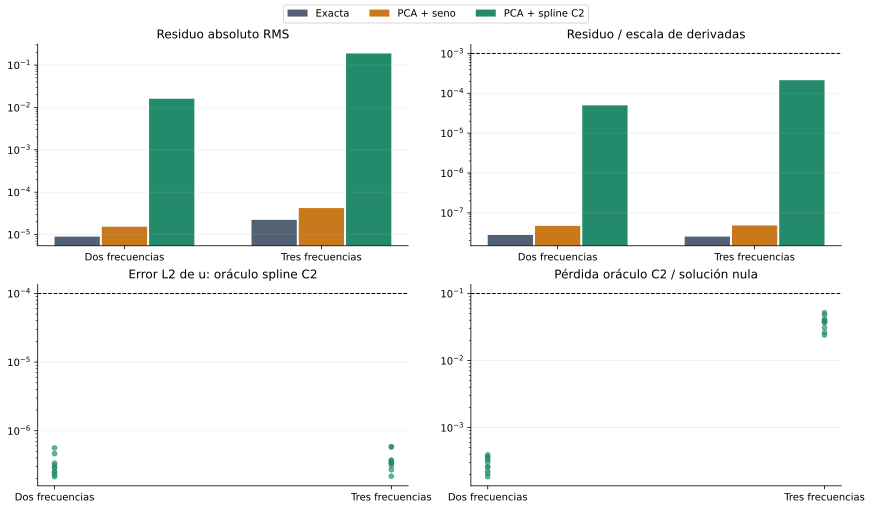

In [ ]:
display(SVG(filename=str(RUN_DIR/'oracle_physics.svg')))

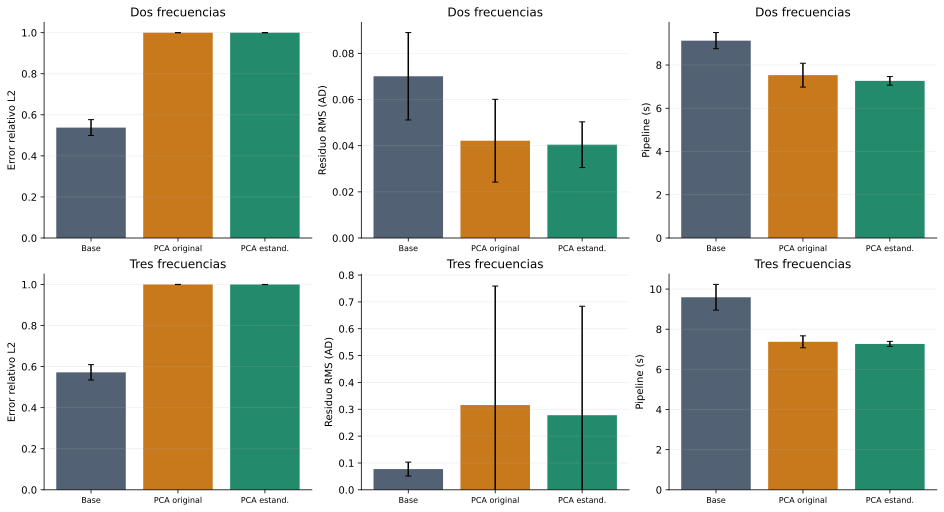

In [ ]:
display(SVG(filename=str(RUN_DIR/'learning_comparison.svg')))

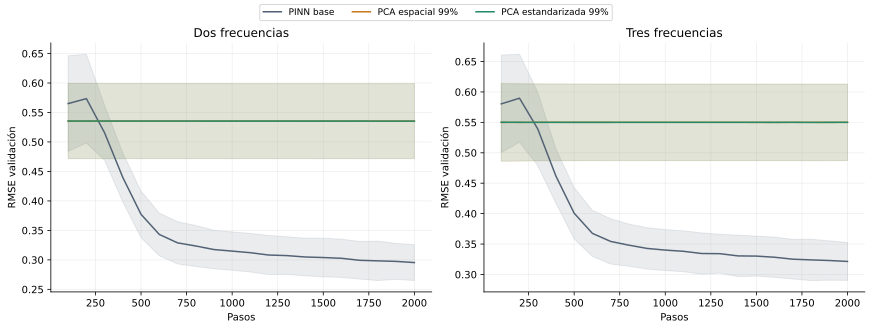

In [ ]:
display(SVG(filename=str(RUN_DIR/'validation_curves.svg')))

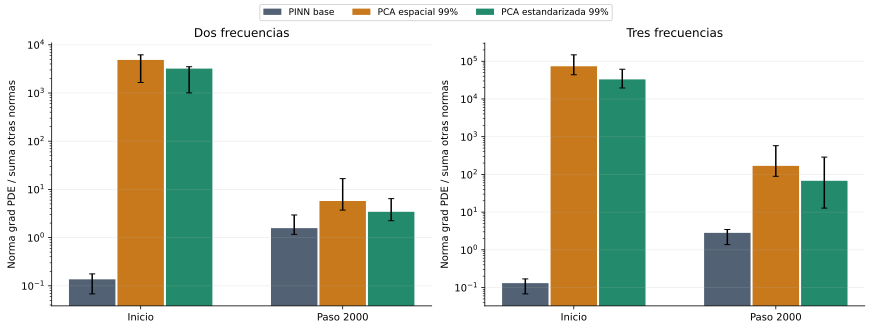

In [ ]:
display(SVG(filename=str(RUN_DIR/'gradient_imbalance.svg')))

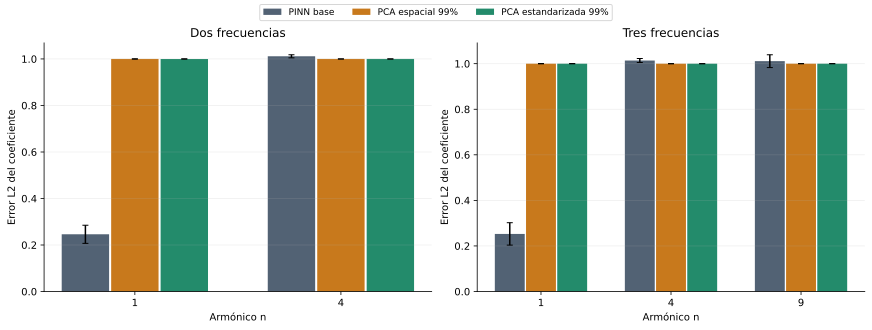

In [ ]:
display(SVG(filename=str(RUN_DIR/'frequency_errors.svg')))

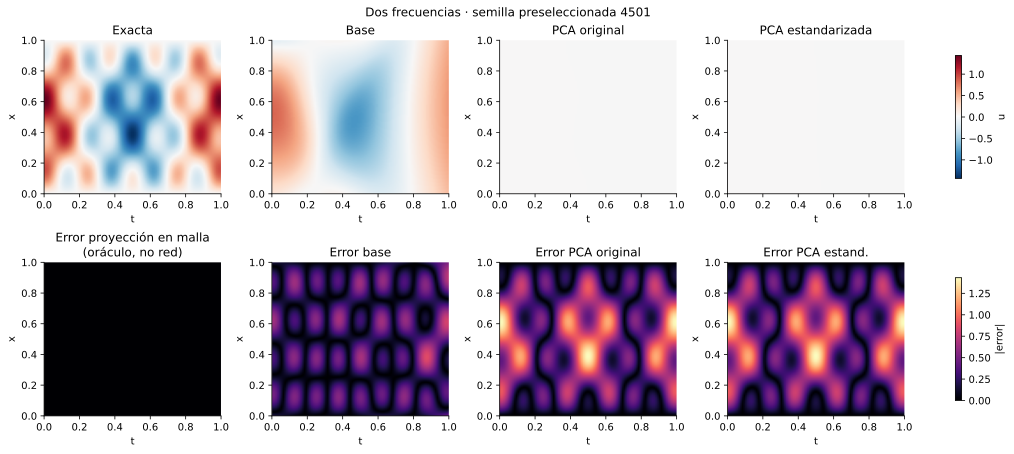

In [ ]:
display(SVG(filename=str(RUN_DIR/'fields_two_frequencies.svg')))

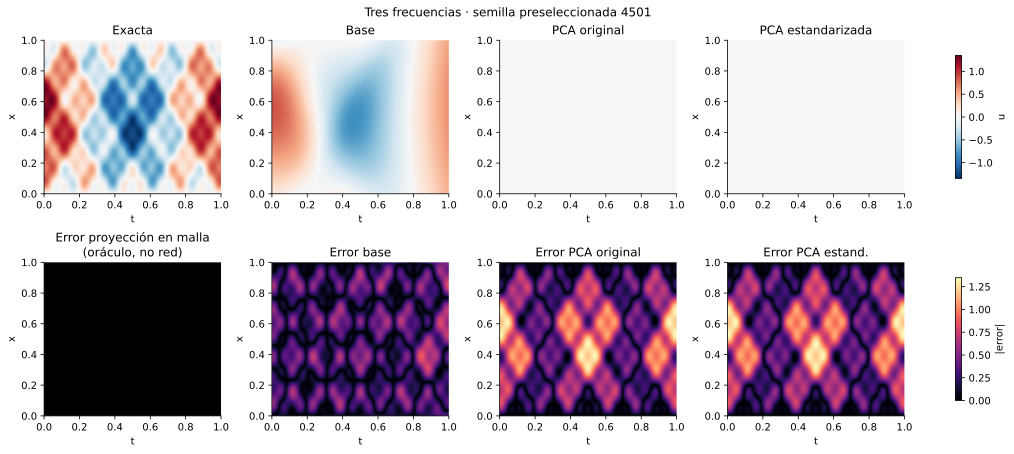

In [ ]:
display(SVG(filename=str(RUN_DIR/'fields_three_frequencies.svg')))

## Interpretación de la ronda

- **two_frequencies**: L2 medio base 0.5378, PCA original 1.0000, PCA estandarizada 0.9999.
- **three_frequencies**: L2 medio base 0.5722, PCA original 1.0001, PCA estandarizada 1.0000.

En esta ejecución, estandarizar por sí solo no corrige el fallo: la diferencia media de L2 es menor que 0.001 y la red estandarizada sigue con error cercano a uno en ambos casos. Los mapas y errores por frecuencia muestran predicciones cercanas a cero. La compresión conserva los datos y el control oráculo puede alcanzar una pérdida mucho menor que la solución nula; la configuración de entrenamiento continúa sin encontrarla.

El oráculo separa capacidad de representar u de precisión de sus derivadas interpoladas. La ablación aísla la estandarización de coeficientes con inicialización física equivalente. Si persiste el colapso, cambiar solo esta escala no corrige la configuración; estos controles no determinan por sí solos si la causa restante es la pérdida, el optimizador, el presupuesto o la red temporal. Un residuo no nulo del spline sigue siendo una limitación numérica que debe conservarse en la interpretación. Los resultados negativos se limitan al protocolo probado y no prueban una imposibilidad general de PCA.

Reproducir: `python scripts/run_wave_diagnostics.py`. Añadir `--oracle-only` para ejecutar solo controles físicos o `--report-only` para actualizar figuras/notebook desde artefactos, sin importar JAX. Se conservan la corrida original, los CSV de oráculos, escaladores y gradientes, las diferencias pareadas y figuras SVG/PNG en la carpeta de esta ronda.

## Cierre del benchmark de onda multiescala

**Estado: cerrado como estudio exploratorio con resultado negativo para la configuración evaluada.** Fecha de cierre: 26 de octubre de 2026.

### Alcance y evidencia conservada

Se evaluaron las soluciones de dos y tres frecuencias de `u_tt − 4u_xx = 0`, con diez semillas por caso, Adam, 2000 pasos y cinco términos de pérdida de peso uniforme. PCA espacial al 99% retuvo dos y tres componentes, respectivamente. El piloto ejecutó 40 ajustes y el diagnóstico ejecutó 60; 40 de estos últimos repiten los modelos del piloto. Estos ajustes no constituyen 100 réplicas independientes: se conservaron las mismas diez semillas en cada caso.

La ronda final comparó PINN base, PCA original y PCA con coeficientes estandarizados, manteniendo muestras, particiones, k, arquitectura y pérdida. El escalador se ajustó solo con entrenamiento. La transformación inversa de la última capa conservó el campo físico inicial, con diferencia máxima de 2.98e-8. Los 800 checkpoints de base y PCA original reprodujeron exactamente el piloto.

### Conclusiones respaldadas

- **Representación de los datos:** la proyección PCA en la malla de prueba conserva la solución con error L2 cercano a 2.6e-8. El truncamiento espacial no explica por sí solo el error de la red entrenada en estos casos.
- **Entrenamiento:** el L2 medio final de PCA original/estandarizada es 0.999951/0.999885 con dos frecuencias y 1.000070/1.000039 con tres. Las predicciones siguen próximas a cero. Estandarizar los coeficientes por sí solo no produce una mejora práctica.
- **Referencia base:** sus errores L2 medios son 0.537803 y 0.572163. También conserva un error considerable; este presupuesto no establece una solución de alta precisión para ninguna de las dos arquitecturas.
- **Física de la representación:** los controles con coeficientes exactos pasan los criterios prácticos fijados antes de evaluar validación. El spline conserva residuos RMS medios de validación de 0.0161 y 0.1881; la precisión de los valores de u no se traslada automáticamente a sus derivadas. La reconstrucción oráculo puede alcanzar una pérdida mucho menor que la solución nula.
- **Tiempo:** un menor tiempo de pipeline con error de solución mayor no respalda una aceleración a calidad equivalente. La hipótesis de reducción útil del tiempo no queda respaldada por este benchmark.

### Límites de la interpretación

El predominio inicial del gradiente PDE dentro de cada parametrización PCA es compatible con un desequilibrio de optimización. Las normas dependen de las coordenadas de parámetros y esta observación no demuestra una causa única. La pérdida, el optimizador, el presupuesto, la red temporal y la interpolación siguen formando parte del protocolo evaluado.

El resultado negativo corresponde a esta combinación de PCA y PINN, a estos datos y al presupuesto ensayado. No demuestra una imposibilidad general de PCA, ni que la pérdida de información sea la causa del fallo. Los coeficientes exactos se utilizaron exclusivamente como diagnóstico, no como una red entrenada competidora.

### Decisión de cierre

Se conserva el resultado negativo y se detiene la búsqueda de ajustes dentro de este benchmark. Una investigación futura con nuevas pérdidas, optimizadores o presupuestos debe registrarse como un estudio separado, con criterios fijados antes de evaluar sus resultados. La tabla global conserva el estado y las fuentes de esta conclusión.

Corridas de referencia: `two_and_three_frequencies_10_seeds_2k_v1` y `diagnostic_standardized_coefficients_10_seeds_2k_v1`.
